# **Blinkit Data Analysis**

# **Business Context**

Blinkit is a quick-commerce (q-commerce) platform that delivers groceries and household essentials to customers within minutes. The company operates through a network of outlets (dark stores/supermarkets) of varying sizes, types, and locations, each stocking a wide range of item categories — from fresh produce to household goods.

With operations spread across multiple outlet types (Grocery Store, Supermarket Type1/2/3), location tiers (Tier 1/2/3 cities), and outlet sizes (Small, Medium, High), sales performance can vary significantly depending on these factors. Understanding what drives sales at the item and outlet level is critical for inventory planning, outlet expansion strategy, and revenue optimization.

# **Business Objective**

The objective of this analysis is to explore the Blinkit sales dataset to:

1. **Understand the data quality** — identify and treat missing values, duplicates, and inconsistent category labels (e.g., "Low Fat", "LF", "low fat" referring to the same category).
2. **Analyze sales performance** across different dimensions such as Item Type, Item Fat Content, Outlet Size, Outlet Location Type, and Outlet Type.
3. **Identify high and low performing segments** — determine which combinations of outlet characteristics (location, size, type) and item attributes correlate with higher sales.
4. **Generate actionable insights** that can help Blinkit:
   - Optimize product assortment and stocking decisions by outlet type/location.
   - Identify underperforming item categories or outlet segments.
   - Support data-driven decisions for future outlet expansion and inventory allocation.

This analysis is exploratory in nature and aims to surface patterns in the data that can guide further business and strategic decisions.

## **Mounting Drive to connect Database**

In [204]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Installing Necessary Packages**

In [205]:
!pip install folium pandas numpy matplotlib seaborn

## **Importing Necessary Packages**

In [206]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## **Importing database into colab**

In [207]:
blinkit = pd.read_csv("/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /Data Analysis/Blinkit Analysis/blinkit_data.csv")
db = blinkit.copy()

In [208]:
Numerical_data = db.select_dtypes(['int64','float']).columns.tolist()
Categorical_data = db.select_dtypes(['object']).columns.tolist()
print(Numerical_data)
print(Categorical_data)

['Outlet Establishment Year', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']
['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type']


## **Viewing First & Last few rows of database**

In [209]:
db.head(7)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,low fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0


In [210]:
db.tail(7)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8516,low fat,FDO38,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.072486,NaN,78.9986,4.0
8517,low fat,FDG32,Fruits and Vegetables,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.175143,NaN,222.3772,4.0
8518,low fat,NCT53,Health and Hygiene,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0
8522,reg,FDM58,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,112.2544,4.0


## **Viewing the shape of the data**

In [211]:
print(f"The database contains {db.shape[0]} rows and {db.shape[1]} columns")

The database contains 8523 rows and 12 columns


## **Checking the data types of the Columns**

In [212]:
db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


## **Checking the Duplicate values in the columns**

In [213]:
print(f'The total number of duplicate or repeated values in database are: {db.duplicated().sum()}')

The total number of duplicate or repeated values in database are: 0


## **Checking the number of null or missing values**

In [214]:
print(f'The total number of null or missing values in database are:\n\n {db.isnull().sum()}')

The total number of null or missing values in database are:

 Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64


treating missing values

In [215]:
db['Item Weight'] = db['Item Weight'].fillna(0)
null = db[db['Item Weight'] == 0]
print(null)
db = db[db['Item Weight'] != 0]
db.head()

     Item Fat Content Item Identifier              Item Type  \
9             Low Fat           FDX25                 Canned   
10                 LF           FDX21            Snack Foods   
14            Low Fat           FDH19                   Meat   
18            Low Fat           FDJ56  Fruits and Vegetables   
20            Regular           FDZ07  Fruits and Vegetables   
...               ...             ...                    ...   
8518          low fat           NCT53     Health and Hygiene   
8519          low fat           FDN09            Snack Foods   
8520          low fat           DRE13            Soft Drinks   
8521              reg           FDT50                  Dairy   
8522              reg           FDM58            Snack Foods   

      Outlet Establishment Year Outlet Identifier Outlet Location Type  \
9                          1998            OUT027               Tier 3   
10                         1998            OUT027               Tier 3   
14       

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [216]:
print(f'The total number of null or missing values in database are:\n\n {db.isnull().sum()}')

The total number of null or missing values in database are:

 Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64


## **Describing the database**

In [217]:
db.describe().T

,count,mean,std,min,25%,50%,75%,max
Outlet Establishment Year,7060.0,2013.490935,6.588984,2000.000,2010.000000,2015.000000,2020.000000,2022.00000
Item Visibility,7060.0,0.063963,0.048625,0.000,0.026768,0.052493,0.092774,0.31109
Item Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.35000
Sales,7060.0,141.240683,62.411888,31.490,94.143600,142.729900,186.024000,266.88840
Rating,7060.0,3.965382,0.610523,1.000,4.000000,4.000000,4.200000,5.00000


## **Checking is any value is less 0 or negative value**

In [218]:
Numerical_data = db.select_dtypes(['int64','float'])
Num_features = Numerical_data[['Outlet Establishment Year', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']]
for col in Num_features.columns:
    has_negative = (Num_features[col] < 0).any()
    print(f"{col}: {'Negative values found' if has_negative else 'No negative values'}")

Outlet Establishment Year: No negative values
Item Visibility: No negative values
Item Weight: No negative values
Sales: No negative values
Rating: No negative values


## **Checking the value counts for all categorical columns**

In [219]:
Cat_data = db.select_dtypes(['object'])
cat_features = Cat_data[['Item Type', 'Item Fat Content', 'Outlet Location Type', 'Outlet Type', 'Outlet Size']]
for col in cat_features.columns:
    print(f"Value counts for column '{col}':\n{db[col].value_counts()}\n")

Value counts for column 'Item Type':
Item Type
Fruits and Vegetables    1019
Snack Foods               988
Household                 759
Frozen Foods              718
Dairy                     566
Canned                    539
Baking Goods              536
Health and Hygiene        430
Soft Drinks               374
Meat                      337
Breads                    204
Hard Drinks               183
Others                    137
Starchy Foods             130
Breakfast                  89
Seafood                    51
Name: count, dtype: int64

Value counts for column 'Item Fat Content':
Item Fat Content
Low Fat    4222
Regular    2388
LF          260
reg         106
low fat      84
Name: count, dtype: int64

Value counts for column 'Outlet Location Type':
Outlet Location Type
Tier 2    2785
Tier 3    2415
Tier 1    1860
Name: count, dtype: int64

Value counts for column 'Outlet Type':
Outlet Type
Supermarket Type1    5577
Supermarket Type2     928
Grocery Store         555
Name: co

In [220]:
db['Item Fat Content'] = db['Item Fat Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})

In [221]:
Cat_data = db.select_dtypes(['object'])
cat_features = Cat_data[['Item Type', 'Item Fat Content', 'Outlet Location Type', 'Outlet Type', 'Outlet Size']]
for col in cat_features.columns:
    print(f"Value counts for column '{col}':\n{db[col].value_counts()}\n")

Value counts for column 'Item Type':
Item Type
Fruits and Vegetables    1019
Snack Foods               988
Household                 759
Frozen Foods              718
Dairy                     566
Canned                    539
Baking Goods              536
Health and Hygiene        430
Soft Drinks               374
Meat                      337
Breads                    204
Hard Drinks               183
Others                    137
Starchy Foods             130
Breakfast                  89
Seafood                    51
Name: count, dtype: int64

Value counts for column 'Item Fat Content':
Item Fat Content
Low Fat    4566
Regular    2494
Name: count, dtype: int64

Value counts for column 'Outlet Location Type':
Outlet Location Type
Tier 2    2785
Tier 3    2415
Tier 1    1860
Name: count, dtype: int64

Value counts for column 'Outlet Type':
Outlet Type
Supermarket Type1    5577
Supermarket Type2     928
Grocery Store         555
Name: count, dtype: int64

Value counts for column 'Outl

## **Converting all Categorical values into numerical values**

In [222]:
db['Outlet Location Type'] = db['Outlet Location Type'].replace({'Tier 1': 1, 'Tier 2': 2, 'Tier 3': 3})
db['Outlet Type'] = db['Outlet Type'].replace({'Supermarket Type1': 1, 'Supermarket Type2': 2, 'Grocery Store': 3, 'Supermarket Type3': 4})
db['Outlet Size'] = db['Outlet Size'].replace({'Small': 1, 'Medium': 2, 'High': 3})
db['Item Fat Content'] = db['Item Fat Content'].replace({'Low Fat': 1, 'Regular': 2})

/tmp/ipykernel_709/1699808835.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  db['Outlet Location Type'] = db['Outlet Location Type'].replace({'Tier 1': 1, 'Tier 2': 2, 'Tier 3': 3})
/tmp/ipykernel_709/1699808835.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  db['Outlet Type'] = db['Outlet Type'].replace({'Supermarket Type1': 1, 'Supermarket Type2': 2, 'Grocery Store': 3, 'Supermarket Type3': 4})
/tmp/ipykernel_709/1699808835.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a fut

In [223]:
db.head(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,2,FDX32,Fruits and Vegetables,2012,OUT049,1,2,1,0.100014,15.10,145.4786,5.0
1,1,NCB42,Health and Hygiene,2022,OUT018,3,2,2,0.008596,11.80,115.3492,5.0
2,2,FDR28,Frozen Foods,2010,OUT046,1,1,1,0.025896,13.85,165.0210,5.0
3,2,FDL50,Canned,2000,OUT013,3,3,1,0.042278,12.15,126.5046,5.0
4,1,DRI25,Soft Drinks,2015,OUT045,2,1,1,0.033970,19.60,55.1614,5.0
5,1,FDS52,Frozen Foods,2020,OUT017,2,1,1,0.005505,8.89,102.4016,5.0
6,1,NCU05,Health and Hygiene,2011,OUT010,3,1,3,0.098312,11.80,81.4618,5.0
7,1,NCD30,Household,2015,OUT045,2,1,1,0.026904,19.70,96.0726,5.0
8,1,FDW20,Fruits and Vegetables,2000,OUT013,3,3,1,0.024129,20.75,124.1730,5.0
11,1,NCU41,Health and Hygiene,2017,OUT035,2,1,1,0.052045,18.85,192.1846,5.0


In [224]:
db['Rating'].value_counts()

,count
Rating,
4.0,2724
4.3,576
4.2,572
4.1,438
5.0,362
4.4,281
3.9,249
4.5,210
3.8,207


In [227]:
db.drop(columns=['Item Identifier', 'Outlet Establishment Year', 'Outlet Identifier'], inplace=True)

In [228]:
db.head(10)

,Item Fat Content,Item Type,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,2,Fruits and Vegetables,1,2,1,0.100014,15.10,145.4786,5.0
1,1,Health and Hygiene,3,2,2,0.008596,11.80,115.3492,5.0
2,2,Frozen Foods,1,1,1,0.025896,13.85,165.0210,5.0
3,2,Canned,3,3,1,0.042278,12.15,126.5046,5.0
4,1,Soft Drinks,2,1,1,0.033970,19.60,55.1614,5.0
5,1,Frozen Foods,2,1,1,0.005505,8.89,102.4016,5.0
6,1,Health and Hygiene,3,1,3,0.098312,11.80,81.4618,5.0
7,1,Household,2,1,1,0.026904,19.70,96.0726,5.0
8,1,Fruits and Vegetables,3,3,1,0.024129,20.75,124.1730,5.0
11,1,Health and Hygiene,2,1,1,0.052045,18.85,192.1846,5.0


In [232]:
db['Sales'].max()

266.8884

# **Exploratory Data Analysis**

# **This section examines the sales performance of Low Fat items across a specific segment of outlets — those located in Tier 1 and Tier 2 cities, with Small or Medium outlet sizes, operating as Supermarket Type 1 or Supermarket Type 2.**

Item Fat Content = Low Fat,   Outlet Location Type = Tier 1,  Outlet Size = Small

Outlet Type = Supermarket Type1, Target = Sales

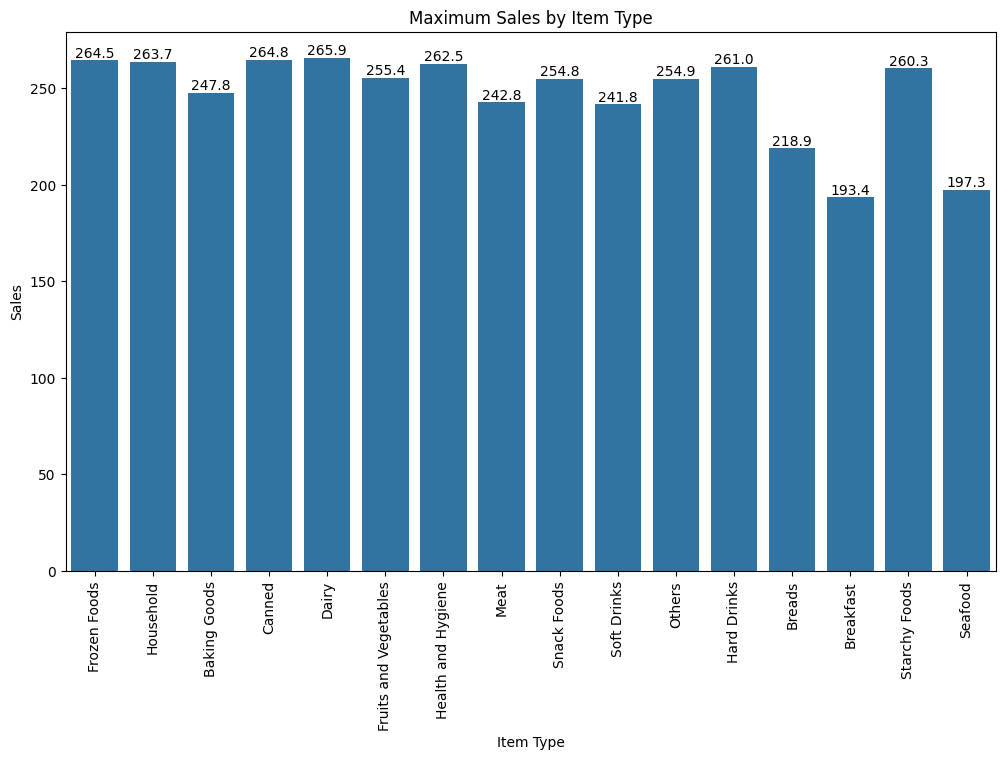

In [245]:
plt.figure(figsize=(12, 7))


First = db[(db['Item Fat Content'] == 1) & (db['Outlet Location Type'] == 1) & (db['Outlet Size'] == 1) & (db['Outlet Type'] == 1)]
ax = sns.barplot(data=First, x='Item Type', y='Sales', estimator='max', errorbar=None)
plt.xticks(rotation=90)
plt.xlabel('Item Type')
plt.ylabel('Sales')
plt.title('Maximum Sales by Item Type')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')  # 1 decimal place

plt.show()

Item Fat Content = Low Fat,   Outlet Location Type = Tier 2,  Outlet Size = Small

Outlet Type = Supermarket Type1, Target = Sales

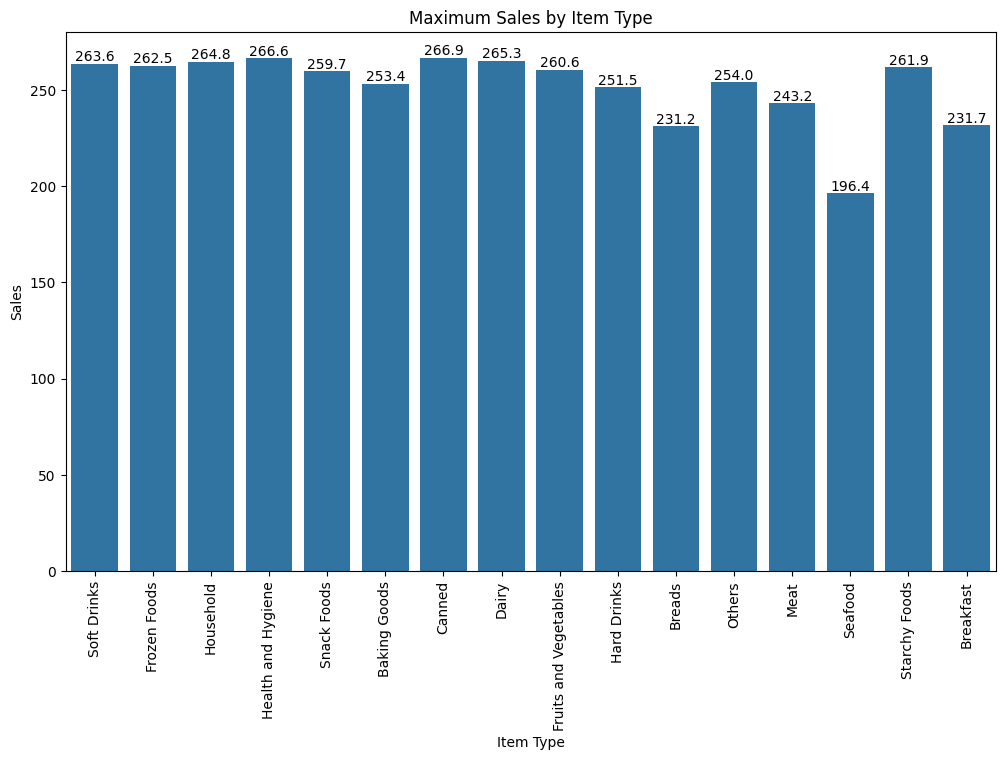

In [246]:
plt.figure(figsize=(12, 7))


First = db[(db['Item Fat Content'] == 1) & (db['Outlet Location Type'] == 2) & (db['Outlet Size'] == 1) & (db['Outlet Type'] == 1)]
ax = sns.barplot(data=First, x='Item Type', y='Sales', estimator='max', errorbar=None)
plt.xticks(rotation=90)
plt.xlabel('Item Type')
plt.ylabel('Sales')
plt.title('Maximum Sales by Item Type')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')  # 1 decimal place

plt.show()

Item Fat Content = Low Fat, Outlet Location Type = Tier 2, Outlet Size = Medium

Outlet Type = Supermarket Type1, Target = Sales

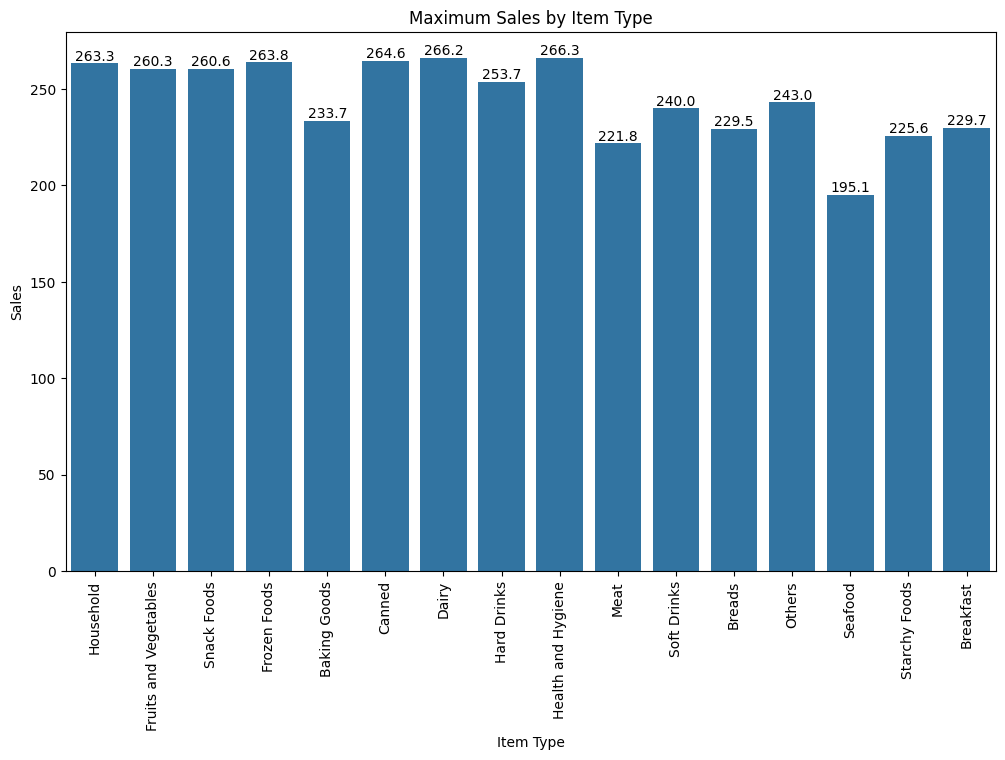

In [249]:
plt.figure(figsize=(12, 7))


second = db[(db['Item Fat Content'] == 1) & (db['Outlet Location Type'] == 1) & (db['Outlet Size'] == 2) & (db['Outlet Type'] == 1)]
ax = sns.barplot(data=second, x='Item Type', y='Sales', estimator='max', errorbar=None)
plt.xticks(rotation=90)
plt.xlabel('Item Type')
plt.ylabel('Sales')
plt.title('Maximum Sales by Item Type')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')  # 1 decimal place

plt.show()

# **This section examines the sales performance of Regular Fat items across a specific segment of outlets — those located in Tier 1 and Tier 2 cities, with Small or Medium outlet sizes, operating as Supermarket Type 1 or Supermarket Type 2**

Item Fat Content = Regular, Outlet Location Type = Tier 1, Outlet Size = small

Outlet Type = Supermarket Type1, Target = Sales

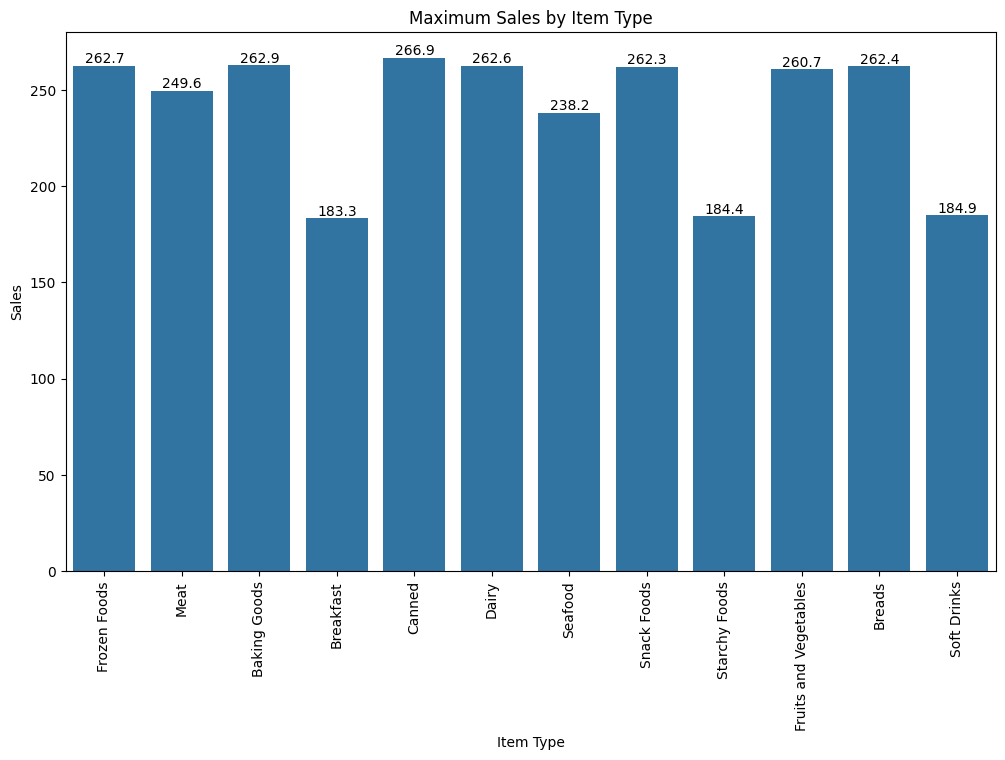

In [264]:
plt.figure(figsize=(12, 7))


second = db[(db['Item Fat Content'] == 2) & (db['Outlet Location Type'] == 1) & (db['Outlet Size'] == 1) & (db['Outlet Type'] == 1)]
ax = sns.barplot(data=second, x='Item Type', y='Sales', estimator='max', errorbar=None)
plt.xticks(rotation=90)
plt.xlabel('Item Type')
plt.ylabel('Sales')
plt.title('Maximum Sales by Item Type')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')  # 1 decimal place

plt.show()

Item Fat Content = Regular, Outlet Location Type = Tier 2, Outlet Size = small

Outlet Type = Supermarket Type1, Target = Sales

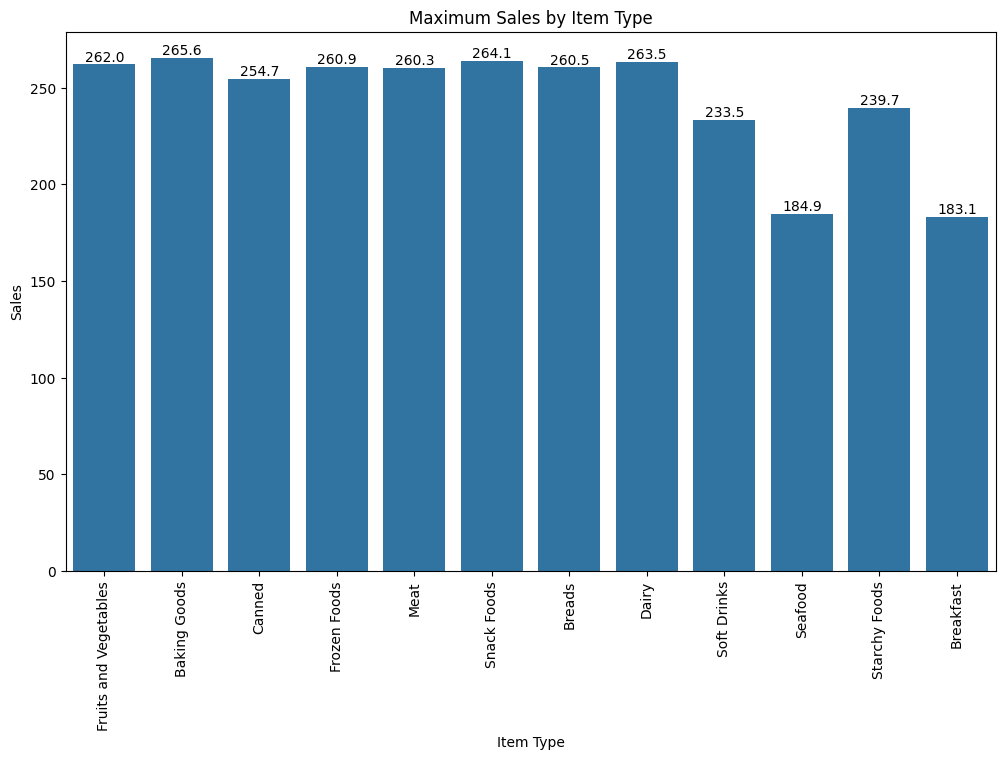

In [265]:
plt.figure(figsize=(12, 7))


second = db[(db['Item Fat Content'] == 2) & (db['Outlet Location Type'] == 2) & (db['Outlet Size'] == 1) & (db['Outlet Type'] == 1)]
ax = sns.barplot(data=second, x='Item Type', y='Sales', estimator='max', errorbar=None)
plt.xticks(rotation=90)
plt.xlabel('Item Type')
plt.ylabel('Sales')
plt.title('Maximum Sales by Item Type')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')  # 1 decimal place

plt.show()

Item Fat Content = Regular, Outlet Location Type = Tier 2, Outlet Size = medium

Outlet Type = Supermarket Type1, Target = Sales

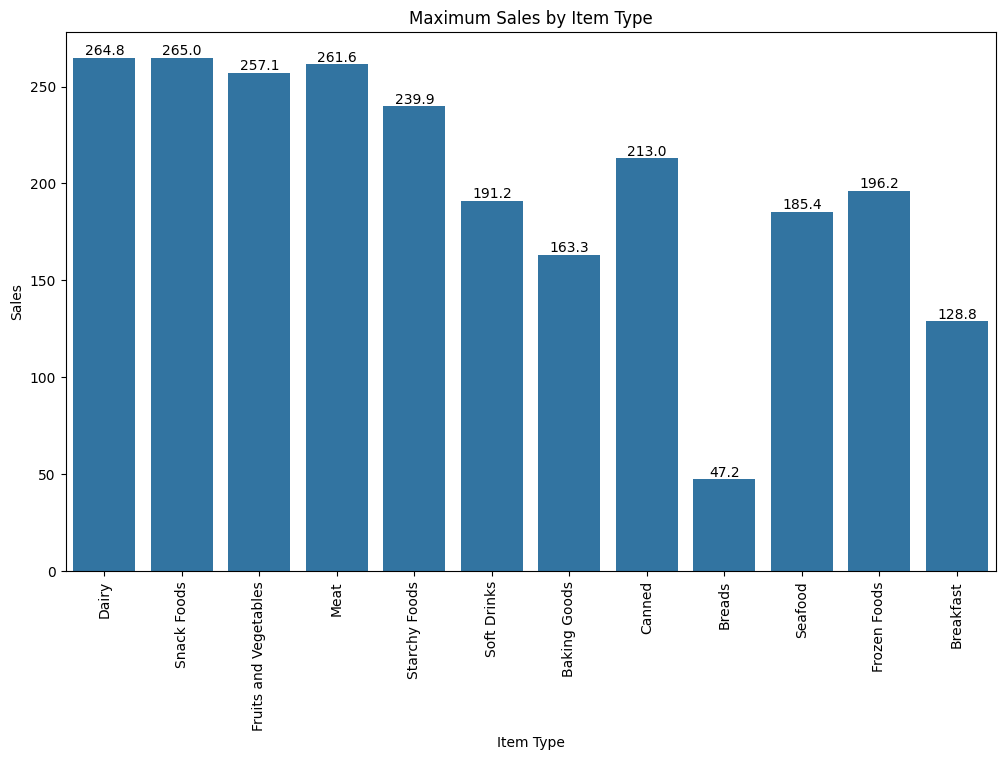

In [268]:
plt.figure(figsize=(12, 7))


second = db[(db['Item Fat Content'] == 2) & (db['Outlet Location Type'] == 2) & (db['Outlet Size'] == 2) & (db['Outlet Type'] == 1)]
ax = sns.barplot(data=second, x='Item Type', y='Sales', estimator='max', errorbar=None)
plt.xticks(rotation=90)
plt.xlabel('Item Type')
plt.ylabel('Sales')
plt.title('Maximum Sales by Item Type')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')  # 1 decimal place

plt.show()

Item Fat Content = Regular, Outlet Location Type = Tier 2, Outlet Size = high

Outlet Type = Supermarket Type1, Target = Sales

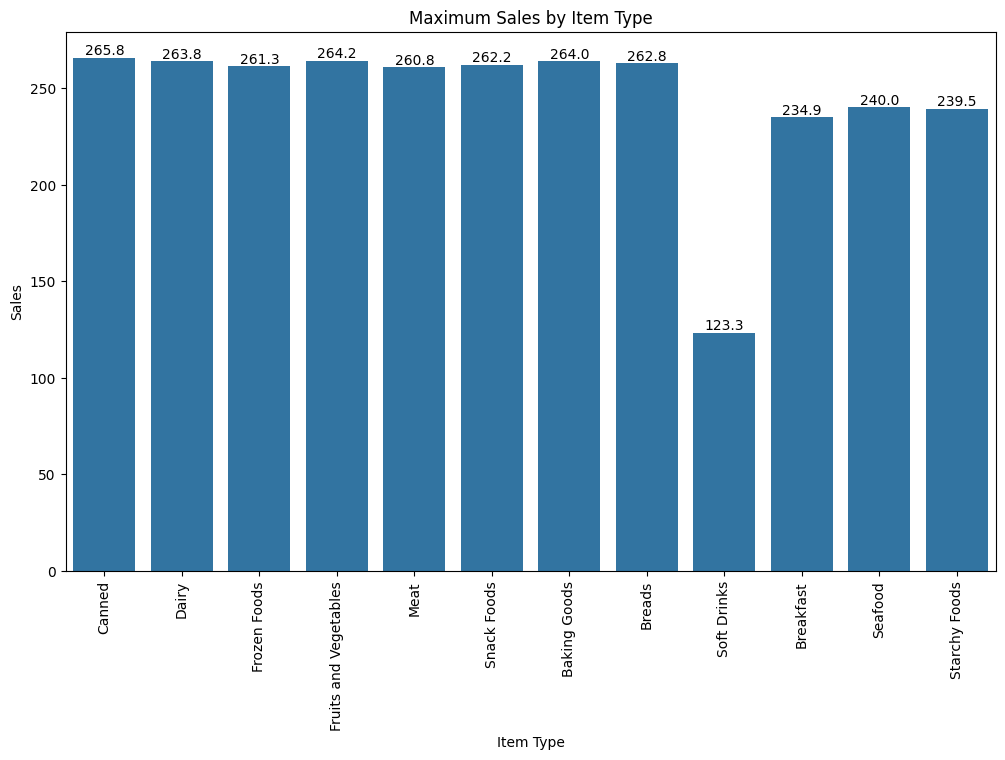

In [272]:
plt.figure(figsize=(12, 7))


second = db[(db['Item Fat Content'] == 2) & (db['Outlet Location Type'] == 2) & (db['Outlet Size'] == 3) & (db['Outlet Type'] == 1)]
ax = sns.barplot(data=second, x='Item Type', y='Sales', estimator='max', errorbar=None)
plt.xticks(rotation=90)
plt.xlabel('Item Type')
plt.ylabel('Sales')
plt.title('Maximum Sales by Item Type')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')  # 1 decimal place

plt.show()